# 05 - Data for Fourier analysis: grain shape (Challenge task 4)

Following the figure on p.5 of the exercise (Ehrlich & Weinberg, 1970): for every grain, measure the **radii from the
centroid to the outline at equally spaced angles**, r(theta), and decompose this periodic signal into **Fourier harmonics**.

| Harmonic n | Shape information |
|---|---|
| 1 | centroid offset (~ 0 by construction: quality check) |
| 2 | elongation |
| 3 | triangularity |
| 4 | squareness |
| 5-14 | roundness / angularity of the corners |
| > 14 | surface texture |

Two complementary descriptors:
1. **Centroid-radius Fourier series** (Ehrlich & Weinberg, 1970; Full & Ehrlich, 1982). This is the classical method
   in the exercise figure. It needs star-shaped outlines (each ray meets the outline once).
2. **Elliptic Fourier descriptors, EFD** (Kuhl & Giardina, 1982). They decompose x(t), y(t) along the outline, work for
   *any* closed outline, and are normalised for size, rotation and starting point. They are used for PCA shape space
   and clustering (data mining).

Data: grains from the **large image**, interior only (not touching the border), equivalent diameter >= 20 Lpx.
The resolution test in section 3 explains this limit.

**Why this matters.** Challenge 4 asks for the data for a Fourier analysis of grain shape. Grain shape records the
sediment's history: transport rounds grains, and different sources give different shapes. Fourier analysis turns an
outline into a few numbers (harmonics) that can be compared and analysed statistically.

**Structure of this notebook**
1. Validate the method on shapes with known answers.
2. Measure r(theta) for every grain: the data for Fourier analysis (as in the exercise figure).
3. Find which harmonics can be trusted at this image resolution.
4. Average spectrum and simple shape indices.
5. Does shape depend on grain size?
6. Shape space (PCA): the main ways grain shapes differ.
7. Are there distinct shape families, and is shape spatially grouped? (plus a robustness check)
8. Grain fabric: do the long axes point in a preferred direction?
9. Save.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import figstyle; figstyle.install()   # larger text in all figures
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
from skimage import draw
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from segmentation import load_rgb
from shape import (grain_contours, polygon_centroid, radial_signature, angular_backtrack,
                   harmonic_amplitudes, efd, efd_power, reconstruct)

plt.rcParams['figure.dpi'] = 90
rgb = load_rgb('../Lamina_alunos_grande.png')
Lg = np.load('../outputs/labels_grain_large.npy')
objs = pd.read_csv('../outputs/03_objects_scaled.csv')
reg = pd.read_csv('../outputs/03_registration.csv', index_col=0).iloc[:, 0].astype(float)
D_MIN, N_ANG, N_HARM, N_RELIABLE = 20, 64, 24, 14

## 1. Validation on synthetic shapes with known answers

**Why.** Before trusting the numbers for real grains, the method must give the right answer for shapes whose harmonics are known in advance.

**Why we calculate it and why it is important.** In one sentence: this section **proves that the method gives the right answer** before we use it on real grains. It is useful for these reasons:

1. **Trust in the results.** If a known ellipse did not give a large A2, or a triangle a large A3, the numbers measured on real grains would mean nothing.
2. **It shows what each harmonic means.** Seeing a triangle light up A3 and a square A4 makes the harmonics of real grains readable.
3. **It checks the centre point.** A1 ~ 0 shows that the radii are measured from the correct centre, which every later number depends on.

| What this section gives | Why it is useful |
|---|---|
| harmonics of shapes with known answers | proves the method works |
| which harmonic lights up for which shape | a key to read the real grains |
| A1 ~ 0 | the centre of each outline is correct |

**What.** A circle, an ellipse, a triangle, a square and a pentagon are drawn as pixel images and measured exactly like the grains. The table gives the amplitude A1-A8 of each harmonic (as a fraction of the mean radius).

In [2]:
def raster(poly, size=200):
    im = np.zeros((size, size), int); rr, cc = draw.polygon(poly[:, 1], poly[:, 0], im.shape); im[rr, cc] = 1; return im
t = np.linspace(0, 2 * np.pi, 400, endpoint=False)
synth = {'circle': np.c_[100 + 50 * np.cos(t), 100 + 50 * np.sin(t)],
         'ellipse 2:1': np.c_[100 + 60 * np.cos(t), 100 + 30 * np.sin(t)],
         'triangle': np.array([[100, 30], [170, 150], [30, 150]]),
         'square': np.array([[50, 50], [150, 50], [150, 150], [50, 150]]),
         'pentagon': np.c_[100 + 60 * np.cos(np.linspace(0, 2 * np.pi, 5, endpoint=False)), 100 + 60 * np.sin(np.linspace(0, 2 * np.pi, 5, endpoint=False))]}
rows = {}
for k, p in synth.items():
    xy = grain_contours(raster(p))[1]; r, star = radial_signature(xy, N_ANG)
    rows[k] = dict(zip([f'A{n}' for n in range(1, 9)], harmonic_amplitudes(r, 8)))
pd.DataFrame(rows).T.round(3)

,A1,A2,A3,A4,A5,A6,A7,A8
circle,0.000,0.000,0.000,0.002,0.000,0.000,0.000,0.001
ellipse 2:1,0.000,0.339,0.000,0.086,0.000,0.027,0.000,0.006
triangle,0.004,0.003,0.277,0.004,0.002,0.104,0.003,0.000
square,0.000,0.000,0.000,0.141,0.000,0.000,0.000,0.046
pentagon,0.002,0.001,0.001,0.002,0.085,0.000,0.000,0.000


Each shape puts its energy where theory says: the ellipse in A2 (and even harmonics), the triangle in A3 (and A6),
the square in A4, the pentagon in A5. A1 ~ 0 confirms the area centroid is used correctly.

## 2. Radial signatures of the grains (the data for Fourier analysis)

**Why.** This is the data Challenge 4 asks for: the outline of each grain described by its radii, as in the figure on page 5 of the exercise.

**Why we calculate it and why it is important.** In one sentence: this section **produces the data Challenge 4 asks for**: every grain outline turned into numbers. It is useful for these reasons:

1. **It answers Challenge 4 directly** (data for Fourier analysis), following the method of the figure on page 5 of the exercise (Ehrlich & Weinberg, 1970).
2. **It turns shapes into numbers.** An outline cannot be averaged or compared statistically; 64 radii and their harmonics can.
3. **Size is removed.** Dividing by the mean radius keeps only the shape, so small and large grains can be compared.
4. **It is the input of everything that follows** in this notebook, and is saved for any further analysis.

| What this section gives | Why it is useful |
|---|---|
| 64 normalised radii per grain | the data for Fourier analysis (Challenge 4) |
| Fourier amplitudes per grain | shape described by a few numbers |
| the exercise figure for real grains | shows how outline, r(theta) and spectrum relate |

**What.** For each grain (large image, not touching the border, diameter >= 20 Lpx): 64 radii from the centre to the outline at equal angles (every 5.6 deg), divided by the mean radius so that grain size does not matter. They are then decomposed into Fourier harmonics.

In [3]:
sel = objs[(objs.image == 'large') & (objs.phase == 'grain') & ~objs.on_border & (objs.eq_diameter_u >= D_MIN)].set_index('label')
cont = grain_contours(Lg, set(sel.index))
R, A, E, P, star, back = {}, {}, {}, {}, {}, {}
for lab, xy in cont.items():
    r, s = radial_signature(xy, N_ANG)
    R[lab], star[lab], back[lab] = r, s, angular_backtrack(xy)
    A[lab] = harmonic_amplitudes(r, N_HARM)
    E[lab] = efd(xy, order=N_RELIABLE)
    P[lab] = efd_power(E[lab])
labs = np.array(sorted(cont))
g = sel.loc[labs].copy()
g['star_shaped'] = [star[l] for l in labs]; g['backtrack_deg'] = [back[l] for l in labs]
amp = pd.DataFrame(np.array([A[l] for l in labs]), index=labs, columns=[f'A{n}' for n in range(1, N_HARM + 1)])
print(f'{len(labs)} grains (D >= {D_MIN} Lpx); star-shaped (backtrack <= 5 deg): {g.star_shaped.mean():.1%}')

# export: radii at 64 angles (normalised by mean radius) + harmonic amplitudes
rad = pd.DataFrame(np.array([R[l] / R[l].mean() for l in labs]), index=labs,
                   columns=[f'r_{int(round(a))}deg' for a in np.degrees(np.linspace(0, 2 * np.pi, N_ANG, endpoint=False))])
pd.concat([g[['cx', 'cy', 'eq_diameter_u', 'star_shaped']], rad], axis=1).to_csv('../outputs/05_radial_signatures.csv', index_label='label')
pd.concat([g[['cx', 'cy', 'eq_diameter_u', 'star_shaped']], amp], axis=1).to_csv('../outputs/05_harmonic_amplitudes.csv', index_label='label')
rad.iloc[:3, :8].round(3)

760 grains (D >= 20 Lpx); star-shaped (backtrack <= 5 deg): 69.2%


,r_0deg,r_6deg,r_11deg,r_17deg,r_22deg,r_28deg,r_34deg,r_39deg
62,0.818,0.805,0.757,0.762,0.736,0.746,0.791,0.851
64,1.056,0.900,0.735,0.638,0.587,0.568,0.504,0.442
68,0.968,0.885,0.824,0.776,0.741,0.690,0.631,0.622


**Reading the result.** 760 grains are measured. 69 % are **star-shaped** (every ray from the centre crosses the
outline once), as the radial method requires; for the others the outer outline is used, and the elliptic Fourier
method (section 6) handles them fully. The table shows the first 8 of the 64 normalised radii for three grains
(1 = mean radius): these rows, saved to `05_radial_signatures.csv`, are the input data for the Fourier analysis.

### Reproducing the exercise figure for real grains
Left: grain outline with 16 of the 64 radii (R1 at 0 deg, counter-clockwise). Middle: r(theta) unrolled over 0-360 deg.
Right: harmonic amplitude spectrum (shaded = harmonics beyond the resolution limit).

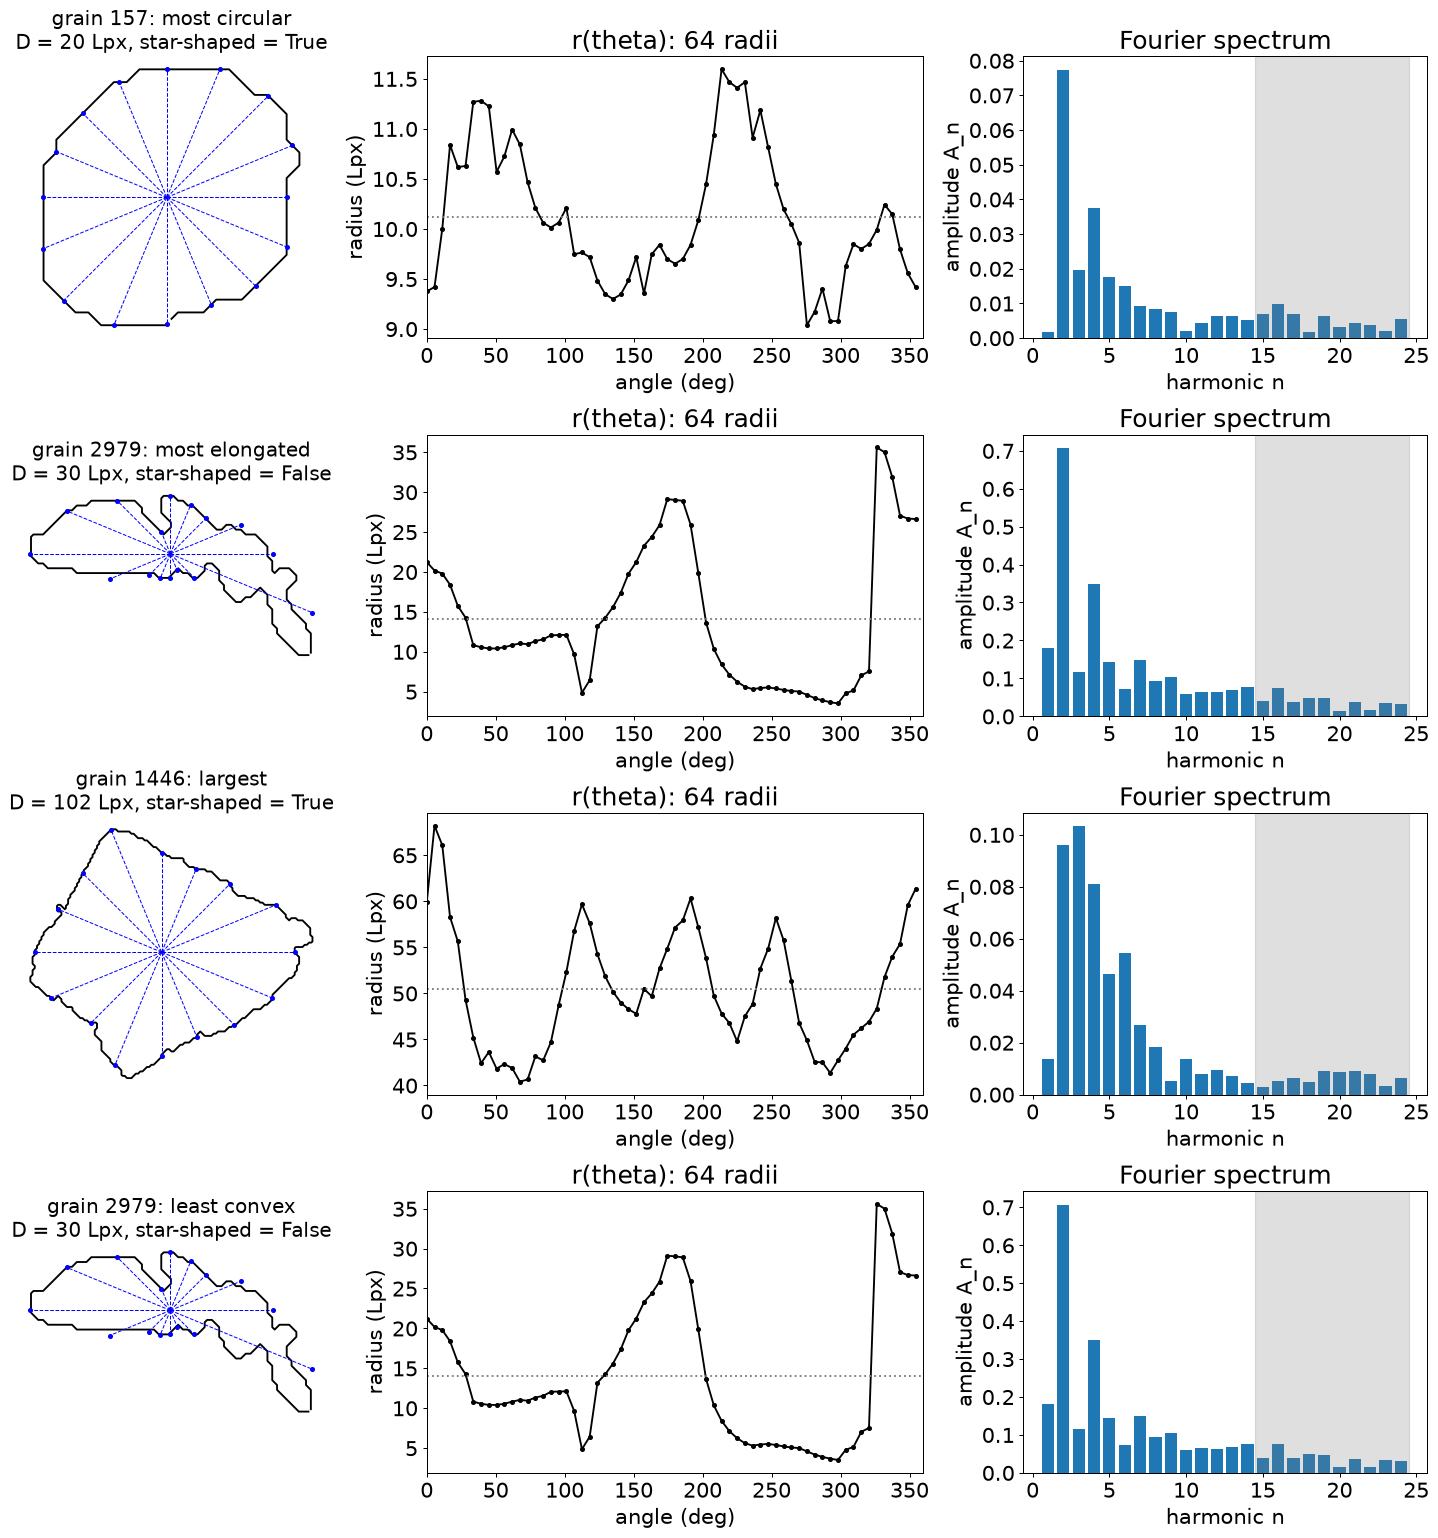

In [4]:
pick = [g.circularity.idxmax(), g.aspect_ratio.idxmax(), g.eq_diameter_u.idxmax(), g.solidity.idxmin()]
names = ['most circular', 'most elongated', 'largest', 'least convex']
fig, ax = plt.subplots(len(pick), 3, figsize=(16, 4.3 * len(pick)), gridspec_kw={'width_ratios': [1, 1.6, 1.3]})
ang = np.linspace(0, 2 * np.pi, N_ANG, endpoint=False)
for i, (lab, nm) in enumerate(zip(pick, names)):
    xy = cont[lab]; c = polygon_centroid(xy); r = R[lab]
    th_img = np.linspace(-np.pi, np.pi, N_ANG, endpoint=False)          # angles used by radial_signature
    order = np.argsort(np.mod(-th_img, 2 * np.pi))                        # to counter-clockwise (y axis points down)
    rr, aa = r[order], np.mod(-th_img, 2 * np.pi)[order]
    a0 = ax[i, 0]; a0.plot(xy[:, 0] - c[0], -(xy[:, 1] - c[1]), 'k', lw=1.5)
    for j in range(0, N_ANG, 4):
        a0.plot([0, rr[j] * np.cos(aa[j])], [0, rr[j] * np.sin(aa[j])], 'b--', lw=0.8)
        a0.plot(rr[j] * np.cos(aa[j]), rr[j] * np.sin(aa[j]), 'bo', ms=3)
    a0.set_aspect('equal'); a0.axis('off'); a0.set_title(f'grain {lab}: {nm}\nD = {g.loc[lab, "eq_diameter_u"]:.0f} Lpx, star-shaped = {star[lab]}')
    ax[i, 1].plot(np.degrees(aa), rr, 'k.-'); ax[i, 1].axhline(r.mean(), color='gray', ls=':')
    ax[i, 1].set_xlabel('angle (deg)'); ax[i, 1].set_ylabel('radius (Lpx)'); ax[i, 1].set_xlim(0, 360); ax[i, 1].set_title('r(theta): 64 radii')
    ax[i, 2].bar(range(1, N_HARM + 1), A[lab], color='tab:blue'); ax[i, 2].axvspan(N_RELIABLE + 0.5, N_HARM + 0.5, color='gray', alpha=0.25)
    ax[i, 2].set_xlabel('harmonic n'); ax[i, 2].set_ylabel('amplitude A_n'); ax[i, 2].set_title('Fourier spectrum')
plt.tight_layout(); plt.show()

**Reading the figure** (one row per example grain).
- **Left:** the grain outline with 16 of the 64 radii (dashed blue), from the centre to the outline.
- **Centre, x axis:** angle around the grain (0-360 deg). **y axis:** radius (Lpx). The dotted line is the mean radius.
  A round grain gives an almost flat line; an elongated grain gives two peaks (the two ends); a triangular grain
  three peaks.
- **Right, x axis:** harmonic number n. **y axis:** amplitude A_n, how strongly the r(theta) curve contains a wave
  with n peaks per turn. Two peaks -> large A2 (elongation), three -> A3, and so on. The grey zone (n > 14) is beyond
  the resolution limit (section 3).

## 3. Which harmonics are real? Resolution test with the two images

**Why.** High harmonics describe fine details of the outline. At some point these details are smaller than a pixel, and the harmonics only measure pixel noise. We need to know where that limit is.

**Why we calculate it and why it is important.** In one sentence: this section finds **which shape details the image is sharp enough to measure**. It is useful for these reasons:

1. **It avoids measuring noise.** High harmonics describe details smaller than a pixel; beyond some point they only measure pixelation, and using them would add false information.
2. **It uses an independent test.** The same grains appear in both images at different resolutions: real shape information must agree, noise will not.
3. **It sets the limits of the study.** It tells which parts of grain shape can be discussed (form, roundness) and which cannot (surface texture) with these images.

| What this section gives | Why it is useful |
|---|---|
| reproducibility of each harmonic | which harmonics can be trusted |
| the limit n = 14 | all later analysis uses only reliable harmonics |
| form and roundness measurable, texture not | what this data can and cannot answer |

**What.** The same grains measured in both images (which have different resolutions) and their harmonics compared. Real harmonics give the same value in both images.

**How.**

The small image is the same rock at 1.19x higher magnification (notebook 03), so the same grains are imaged twice at
different resolutions. We match grains between the images (centroid within 3 Lpx, area within 15 %) and compare
their amplitudes harmonic by harmonic. Harmonics measured reliably should agree (high rank correlation).
Harmonics dominated by pixelation will not.

matched grains: 281  (of which D >= 20: 151)


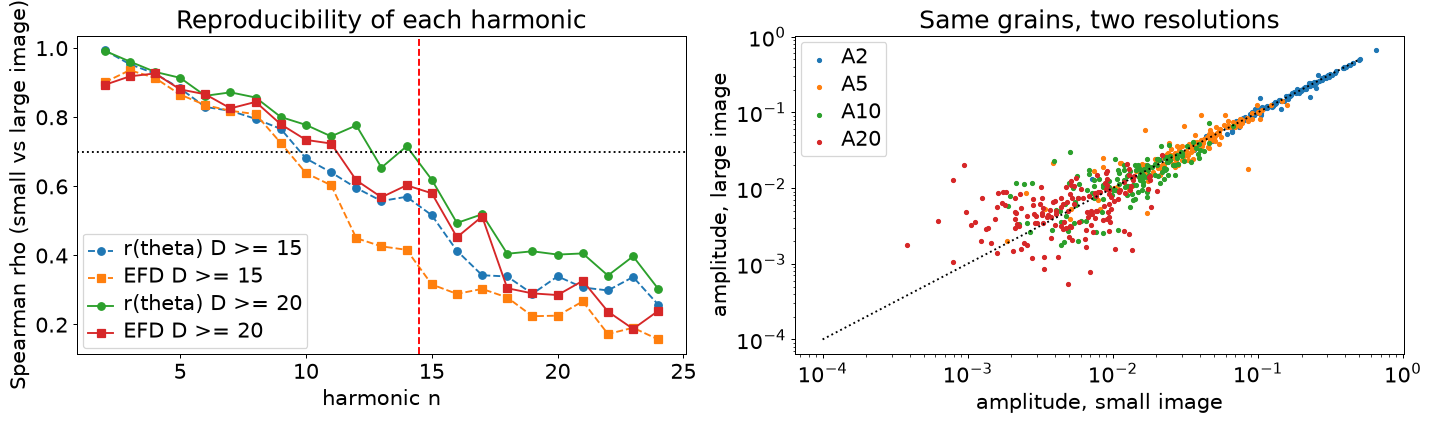

In [5]:
Ls = np.load('../outputs/labels_grain_small.npy')
S = objs[(objs.image == 'small') & (objs.phase == 'grain') & ~objs.on_border & (objs.eq_diameter_u >= 15)].reset_index(drop=True)
Lall = objs[(objs.image == 'large') & (objs.phase == 'grain') & ~objs.on_border].reset_index(drop=True)
dist, idx = cKDTree(Lall[['cx', 'cy']].values).query(np.c_[reg.x0 + S.cx * reg.scale_small_to_large, reg.y0 + S.cy * reg.scale_small_to_large])
M = Lall.iloc[idx].reset_index(drop=True)
ok = (dist < 3) & (np.abs(S.area_u / M.area_u - 1) < 0.15)
S, M = S[ok], M[ok]
cs, cl = grain_contours(Ls, set(S.label)), grain_contours(Lg, set(M.label))
As = np.array([harmonic_amplitudes(radial_signature(cs[a], N_ANG)[0], N_HARM) for a in S.label])
Al = np.array([harmonic_amplitudes(radial_signature(cl[b], N_ANG)[0], N_HARM) for b in M.label])
Es = np.array([efd_power(efd(cs[a], N_HARM)) for a in S.label]); El = np.array([efd_power(efd(cl[b], N_HARM)) for b in M.label])
Dm = M.eq_diameter_u.values
print(f'matched grains: {ok.sum()}  (of which D >= {D_MIN}: {(Dm >= D_MIN).sum()})')

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
n = np.arange(2, N_HARM + 1)
for sub, lbl, st in [(Dm >= 15, 'D >= 15', '--'), (Dm >= D_MIN, f'D >= {D_MIN}', '-')]:
    ax[0].plot(n, [stats.spearmanr(As[sub, k - 1], Al[sub, k - 1]).statistic for k in n], 'o' + st, label=f'r(theta) {lbl}')
    ax[0].plot(n, [stats.spearmanr(Es[sub, k - 1], El[sub, k - 1]).statistic for k in n], 's' + st, label=f'EFD {lbl}')
ax[0].axhline(0.7, color='k', ls=':'); ax[0].axvline(N_RELIABLE + 0.5, color='r', ls='--')
ax[0].set_xlabel('harmonic n'); ax[0].set_ylabel('Spearman rho (small vs large image)'); ax[0].legend(); ax[0].set_title('Reproducibility of each harmonic')
sub = Dm >= D_MIN
for k, c in [(2, 'tab:blue'), (5, 'tab:orange'), (10, 'tab:green'), (20, 'tab:red')]:
    ax[1].scatter(As[sub, k - 1], Al[sub, k - 1], s=10, color=c, label=f'A{k}')
lim = [1e-4, 0.5]; ax[1].plot(lim, lim, 'k:'); ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('amplitude, small image'); ax[1].set_ylabel('amplitude, large image'); ax[1].legend(); ax[1].set_title('Same grains, two resolutions')
plt.tight_layout(); plt.show()

**Reading the plots.**
- **Left, x axis:** harmonic number n. **y axis:** Spearman rho between the amplitude measured in the small and in the
  large image for the same grains (1 = identical ranking, 0 = unrelated). Circles = radial method, squares = elliptic
  Fourier; solid = grains >= 20 Lpx. Above the dotted line (0.7) the harmonic is reproducible; the red dashed line
  marks n = 14.
- **Right:** each dot is one grain, amplitude in the small image (x) against the large image (y), for four harmonics.
  A2 (blue) lies on the diagonal; A20 (red) is scattered.

**Result**: for grains >= 20 Lpx, harmonics **2 to ~14** reproduce well between the two resolutions (rho >= ~0.7).
Above ~16 the agreement collapses: these harmonics are dominated by pixelation. So **form (2-4) and roundness (5-14)
are measurable, while surface texture (> 14) is not resolved** in these images. We restrict the analysis to n <= 14.

## 4. Mean amplitude spectrum and shape indices

**Why.** The 24 amplitudes per grain are hard to interpret one by one. Averaging them and grouping them into a few indices gives a readable summary, and checking them against simple descriptors confirms what they mean.

**Why we calculate it and why it is important.** In one sentence: this section **summarises the shape of all grains** and checks what the Fourier numbers mean. It is useful for these reasons:

1. **It gives the typical grain shape** of the rock in a few numbers.
2. **It groups the harmonics into meaningful indices**: gross form (A2-A4) and angularity of corners (A5-A14), the two classical components of grain shape.
3. **It links Fourier to familiar descriptors.** Strong agreement with aspect ratio, circularity and solidity shows the Fourier indices measure what they are supposed to.
4. **Quality control.** A1 ~ 0 on the real grains confirms the measurements are correct.

| What this section gives | Why it is useful |
|---|---|
| median spectrum of all grains | the typical grain shape |
| form and roundness indices | shape summarised in two meaningful numbers |
| agreement with notebook 03 descriptors | confirms what the indices mean |

**What.** The median spectrum of all grains, two indices (**form** = combined A2-A4, gross shape; **roundness_h** = combined A5-A14, angularity of the corners), and their correlation with the descriptors of notebook 03.

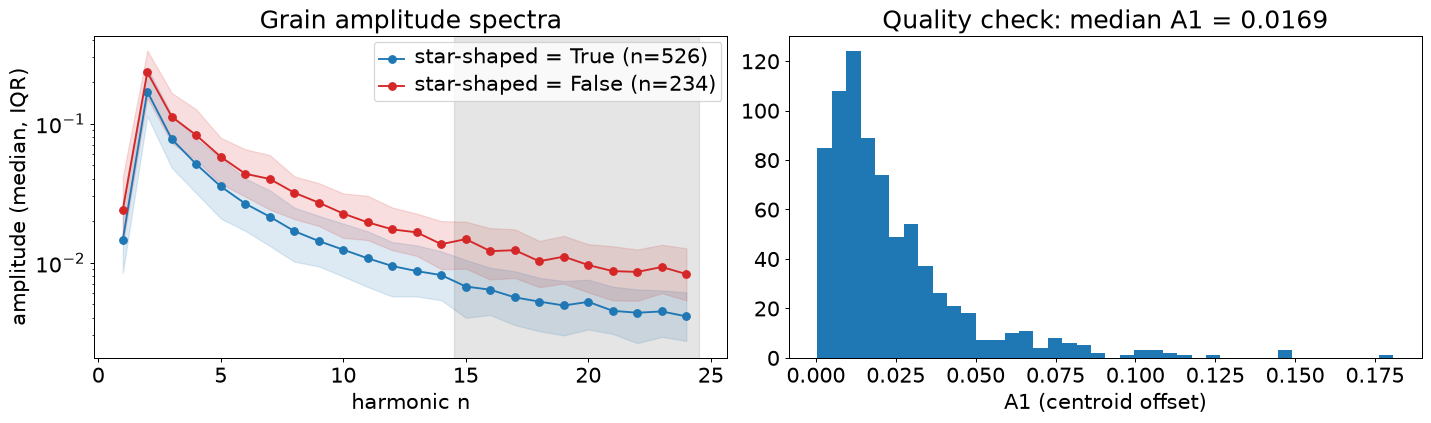

,Fourier index,classical descriptor,Spearman rho
0,A2,aspect_ratio,0.98
1,form,aspect_ratio,0.87
2,roundness_h,circularity,-0.84
3,roundness_h,solidity,-0.86
4,form,circularity,-0.65


In [6]:
rel = [f'A{n}' for n in range(2, N_RELIABLE + 1)]
g['form'] = np.sqrt((amp[['A2', 'A3', 'A4']] ** 2).sum(1))                       # gross form
g['roundness_h'] = np.sqrt((amp[[f'A{n}' for n in range(5, N_RELIABLE + 1)]] ** 2).sum(1))   # corner angularity
g['A2'] = amp['A2']; g['A1'] = amp['A1']

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for s, c in [(True, 'tab:blue'), (False, 'tab:red')]:
    a = amp[g.star_shaped.values == s]
    ax[0].plot(range(1, N_HARM + 1), a.median(), 'o-', color=c, label=f'star-shaped = {s} (n={len(a)})')
    ax[0].fill_between(range(1, N_HARM + 1), a.quantile(0.25), a.quantile(0.75), color=c, alpha=0.15)
ax[0].set_yscale('log'); ax[0].axvspan(N_RELIABLE + 0.5, N_HARM + 0.5, color='gray', alpha=0.2)
ax[0].set_xlabel('harmonic n'); ax[0].set_ylabel('amplitude (median, IQR)'); ax[0].legend(); ax[0].set_title('Grain amplitude spectra')
ax[1].hist(g.A1, 40); ax[1].set_xlabel('A1 (centroid offset)'); ax[1].set_title(f'Quality check: median A1 = {g.A1.median():.4f}')
plt.tight_layout(); plt.show()

# consistency with classical descriptors
pairs = [('A2', 'aspect_ratio'), ('form', 'aspect_ratio'), ('roundness_h', 'circularity'), ('roundness_h', 'solidity'), ('form', 'circularity')]
pd.DataFrame([{'Fourier index': a, 'classical descriptor': b, 'Spearman rho': stats.spearmanr(g[a], g[b]).statistic} for a, b in pairs]).round(2)

**Reading the result.**
- **Left, x axis:** harmonic number. **y axis:** amplitude (log); line = median, band = middle 50 % of grains. Blue =
  star-shaped grains, red = the others. Amplitudes fall with n: the gross form (n = 2-4) dominates, corners and
  texture are smaller details. A2 is the largest: grains are mainly **elongated**.
- **Right:** histogram of A1 (centre offset) for all grains; it should be ~ 0, and it is (median ~ 0.01): the
  centre is placed correctly.
- **Table:** Spearman rho between the Fourier indices and the classical descriptors. A2 vs aspect ratio = 0.98 and
  roundness_h vs circularity / solidity = -0.84 / -0.86: the Fourier indices measure what they are supposed to.

## 5. Does shape depend on grain size?

**Why.** If small and large grains had different shapes, they could come from different sources or have had different transport histories.

**Why we calculate it and why it is important.** In one sentence: this section tests **whether small and large grains have the same shape**. It is useful for these reasons:

1. **It is a provenance test.** Grains from different sources, or of different sizes transported differently, often have different shapes; a size-shape link would point to mixed sources.
2. **It checks the transport history.** Larger grains are usually rounded faster by abrasion; no difference suggests a uniform history.
3. **It checks the method.** If shape changed with size, part of it could be a resolution effect on small grains.

| What this section gives | Why it is useful |
|---|---|
| shape per size class | same or different shapes for small and large grains |
| trend test with size | provenance and transport history |
| no trend found | a single, uniform population (confirmed in section 7) |

**What.** Grains grouped into four size classes (20-25, 25-30, 30-40, > 40 Lpx) and their elongation (A2), form and roundness_h compared.

**How.**

Ehrlich and co-workers showed that shape distributions within size classes can reveal mixed sediment sources and
abrasion history. We test whether form and roundness change with grain size.

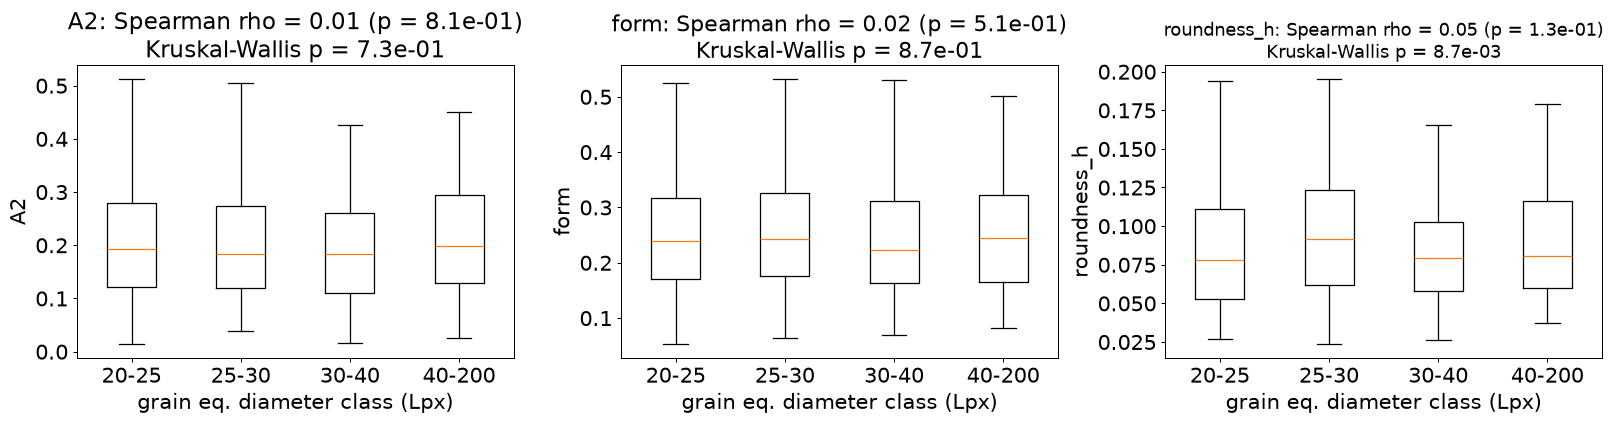

,A2,form,roundness_h,aspect_ratio,circularity,n
size_class,,,,,,
20-25,0.192,0.238,0.078,1.432,0.791,404
25-30,0.183,0.244,0.091,1.445,0.733,172
30-40,0.183,0.224,0.079,1.418,0.729,126
40-200,0.198,0.245,0.080,1.446,0.676,58


In [7]:
bins = [20, 25, 30, 40, 200]
g['size_class'] = pd.cut(g.eq_diameter_u, bins, labels=[f'{a}-{b}' for a, b in zip(bins[:-1], bins[1:])])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, col in zip(ax, ['A2', 'form', 'roundness_h']):
    data = [g.loc[g.size_class == c, col] for c in g.size_class.cat.categories]
    a.boxplot(data, tick_labels=g.size_class.cat.categories, showfliers=False)
    rho = stats.spearmanr(g.eq_diameter_u, g[col])
    kw = stats.kruskal(*data)
    a.set_xlabel('grain eq. diameter class (Lpx)'); a.set_ylabel(col)
    a.set_title(f'{col}: Spearman rho = {rho.statistic:.2f} (p = {rho.pvalue:.1e})\nKruskal-Wallis p = {kw.pvalue:.1e}')
plt.tight_layout(); plt.show()
g.groupby('size_class', observed=True)[['A2', 'form', 'roundness_h', 'aspect_ratio', 'circularity']].median().assign(n=g.size_class.value_counts()).round(3)

**Reading the plots.** **x axis:** size class (equivalent diameter, Lpx). **y axis:** the shape index. Each box
shows the middle 50 % of grains in that class (line = median; whiskers = the usual range). Spearman rho measures a
trend with size, and the Kruskal-Wallis p tests whether the classes differ at all. The boxes are at the same level in
every class (rho ~ 0.01-0.05): **grain shape does not depend on grain size**. The table gives the medians per class.

## 6. Shape space (PCA on EFD harmonic power) - data mining

**Why.** Each grain is described by ~ 14 numbers, many of them related. Principal component analysis (PCA) finds the few independent directions along which grain shapes really differ, a standard data-mining step.

**Why we calculate it and why it is important.** In one sentence: this section finds **the main ways in which grain shapes differ**. It is useful for these reasons:

1. **It simplifies the data.** Each grain has ~ 14 related numbers; PCA reduces them to two or three independent directions that are easy to plot and interpret.
2. **It finds the natural shape axes of the rock.** Here: angularity and elongation, the two classical components of grain shape.
3. **It is the data-mining step** of the Fourier analysis: an unsupervised method that lets the data reveal its structure.
4. **It prepares section 7.** Groups of grains (shape families) are searched in this space.

| What this section gives | Why it is useful |
|---|---|
| principal components | the main independent ways shapes vary |
| PC1 = angularity, PC2 = elongation | interpretable shape axes |
| grid of real grains | makes the axes visible |

**What.** A PCA on the elliptic Fourier harmonics of all grains, then a grid of real grains laid out along the first two components.

**How.**

Feature vector per grain: **elongation** (minor/major ratio of the first EFD ellipse) + **log power of EFD
harmonics 2-14**, standardised. The harmonic power is invariant to rotation, start point and the 180-degree
normalisation ambiguity of EFD. Using log power and standardising gives the subtle higher harmonics (angularity) the
same weight as the dominant elongation term. Without this, raw EFD coefficients put > 80 % of the variance on
elongation alone.

explained variance (%): [43.3  9.8  7.3  5.4  5.   4.4]


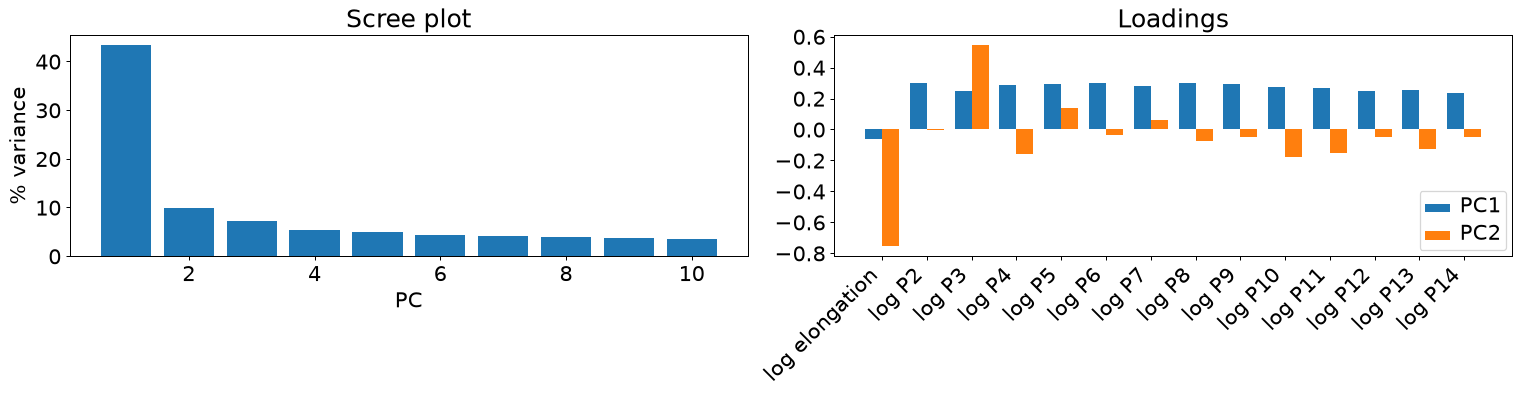

,PC1,PC2,PC3
aspect_ratio,0.07,0.89,-0.17
circularity,-0.87,-0.38,-0.07
solidity,-0.85,-0.33,-0.15
form,0.33,0.81,0.01
roundness_h,0.75,0.36,0.20
eq_diameter_u,0.18,-0.05,-0.11


In [8]:
def canon(c):
    """Fix the 180-degree EFD ambiguity (sign of odd harmonics) for storing coefficients."""
    c = c.copy()
    odd = c[2::2]
    k = np.unravel_index(np.argmax(np.abs(odd)), odd.shape)
    if odd[k] < 0:
        c[2::2] *= -1
    return c

from sklearn.preprocessing import StandardScaler
pw = np.array([P[l] for l in labs])                                  # harmonic power 1..14
elong = np.array([abs(E[l][0, 3]) for l in labs])                     # minor/major of 1st ellipse
feat_names = ['log elongation'] + [f'log P{n}' for n in range(2, N_RELIABLE + 1)]
F = np.c_[np.log(elong), np.log(pw[:, 1:N_RELIABLE])]
Xs = StandardScaler().fit_transform(F)
pca = PCA().fit(Xs); Z = pca.transform(Xs); ev = pca.explained_variance_ratio_
print('explained variance (%):', (100 * ev[:6]).round(1))
pcs = pd.DataFrame(Z[:, :3], index=labs, columns=['PC1', 'PC2', 'PC3'])
# orient axes so PC1 increases with angularity and PC2 with elongation
if stats.spearmanr(pcs.PC1, g.solidity).statistic > 0: pcs['PC1'] *= -1; pca.components_[0] *= -1
if stats.spearmanr(pcs.PC2, g.aspect_ratio).statistic < 0: pcs['PC2'] *= -1; pca.components_[1] *= -1

fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
ax[0].bar(range(1, 11), 100 * ev[:10]); ax[0].set_xlabel('PC'); ax[0].set_ylabel('% variance'); ax[0].set_title('Scree plot')
w = 0.38
ax[1].bar(np.arange(len(feat_names)) - w / 2, pca.components_[0], w, label='PC1')
ax[1].bar(np.arange(len(feat_names)) + w / 2, pca.components_[1], w, label='PC2')
ax[1].set_xticks(range(len(feat_names))); ax[1].set_xticklabels(feat_names, rotation=45, ha='right'); ax[1].legend(); ax[1].set_title('Loadings')
plt.tight_layout(); plt.show()

corr = pd.DataFrame({pc: {d: stats.spearmanr(pcs[pc], g[d]).statistic for d in ['aspect_ratio', 'circularity', 'solidity', 'form', 'roundness_h', 'eq_diameter_u']} for pc in pcs}).round(2)
corr

**Reading the result.**
- **Printed line / left plot (scree plot):** share of the total shape variation explained by each principal component.
  PC1 explains 43 %, PC2 10 %.
- **Right (loadings):** how much each Fourier feature contributes to PC1 and PC2. PC1 draws on all the higher
  harmonics evenly; PC2 draws mainly on the elongation feature.
- **Table:** Spearman rho between the components and the classical descriptors: PC1 follows circularity and solidity
  (-0.87, -0.85) -> **angularity / irregularity**; PC2 follows aspect ratio (0.89) -> **elongation**.

**Interpretation of the axes**: PC1 loads evenly on all higher harmonics and tracks circularity/solidity, so it is an
**angularity / irregularity** axis. PC2 loads on the elongation term and tracks the aspect ratio, so it is an **elongation**
axis. These are the two classical, independent components of grain shape: *form* and *roundness* (Wadell;
Ehrlich & Weinberg, 1970).

### Real grains laid out in shape space
Each cell of a grid over (PC1, PC2) shows the real grain closest to the cell centre, size-normalised.

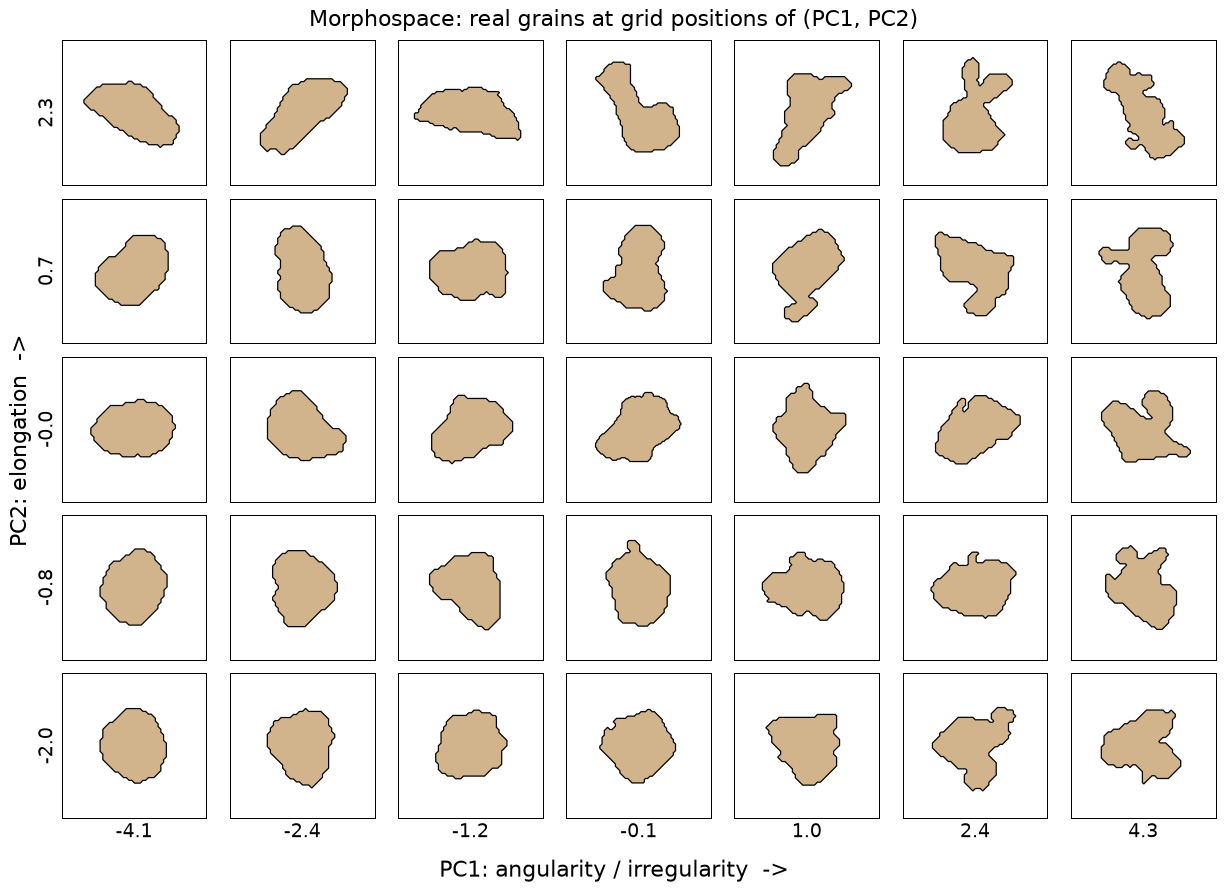

In [9]:
nx_, ny_ = 7, 5
xq = np.quantile(pcs.PC1, np.linspace(0.03, 0.97, nx_)); yq = np.quantile(pcs.PC2, np.linspace(0.03, 0.97, ny_))
tree = cKDTree(pcs[['PC1', 'PC2']].values / pcs[['PC1', 'PC2']].std().values)
fig, ax = plt.subplots(ny_, nx_, figsize=(14, 10))
for i, yv in enumerate(yq[::-1]):
    for j, xv in enumerate(xq):
        _, k = tree.query(np.array([xv, yv]) / pcs[['PC1', 'PC2']].std().values)
        lab = labs[k]; xy = cont[lab] - polygon_centroid(cont[lab]); s = np.sqrt(g.loc[lab, 'area'])
        ax[i, j].fill(xy[:, 0] / s, -xy[:, 1] / s, color='tan', ec='k'); ax[i, j].set_xlim(-1.2, 1.2); ax[i, j].set_ylim(-1.2, 1.2)
        ax[i, j].set_aspect('equal'); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
for j in range(nx_): ax[-1, j].set_xlabel(f'{xq[j]:.1f}')
for i in range(ny_): ax[i, 0].set_ylabel(f'{yq[::-1][i]:.1f}')
fig.supxlabel('PC1: angularity / irregularity  ->'); fig.supylabel('PC2: elongation  ->')
plt.suptitle('Morphospace: real grains at grid positions of (PC1, PC2)'); plt.tight_layout(); plt.show()

**Reading the figure.** Moving right (PC1 up) the grains become more irregular and angular; moving up (PC2 up) they
become more elongated. Bottom left = round and compact, top right = elongated and irregular. The axes are the two
shape properties that vary independently in this rock.

## 7. Are there distinct shape families?

**Why.** Grains from two sources, or with two transport histories, would form two separate groups in shape space. Finding one group or several says something about the sediment's provenance.

**Why we calculate it and why it is important.** In one sentence: this section tests **whether the grains form one population or several**, and whether shape is spatially grouped. It is useful for these reasons:

1. **It is the key provenance question.** Several shape families would indicate several sediment sources or transport histories (Ehrlich et al., 1980); one family indicates a single source.
2. **It links shape to the heterogeneity of notebook 04.** If angular or round grains gathered in zones, grain shape could explain the porous zones.
3. **It checks robustness.** Grains wrongly merged by the segmentation could create false families; the results are recomputed without them.

| What this section gives | Why it is useful |
|---|---|
| number of shape families | one or several sediment sources |
| spatial test of shape (Moran's I) | whether shape explains the porous zones |
| check without aggregates | results do not depend on segmentation errors |

**What.** Gaussian mixture models with 1 to 6 groups are fitted to the first three components; the BIC score picks the number of groups best supported by the data.

**How.**

Several sediment sources, or grains with different abrasion histories, would appear as **separate modes** in shape
space (Ehrlich et al., 1980). We fit Gaussian mixtures with 1-6 components to the first PCs and select by **BIC**.
One component means a single continuous shape population.

BIC (first 3 PCs, lower is better): {1: 8156, 2: 8178, 3: 8242, 4: 8267, 5: 8323, 6: 8376} -> best K = 1


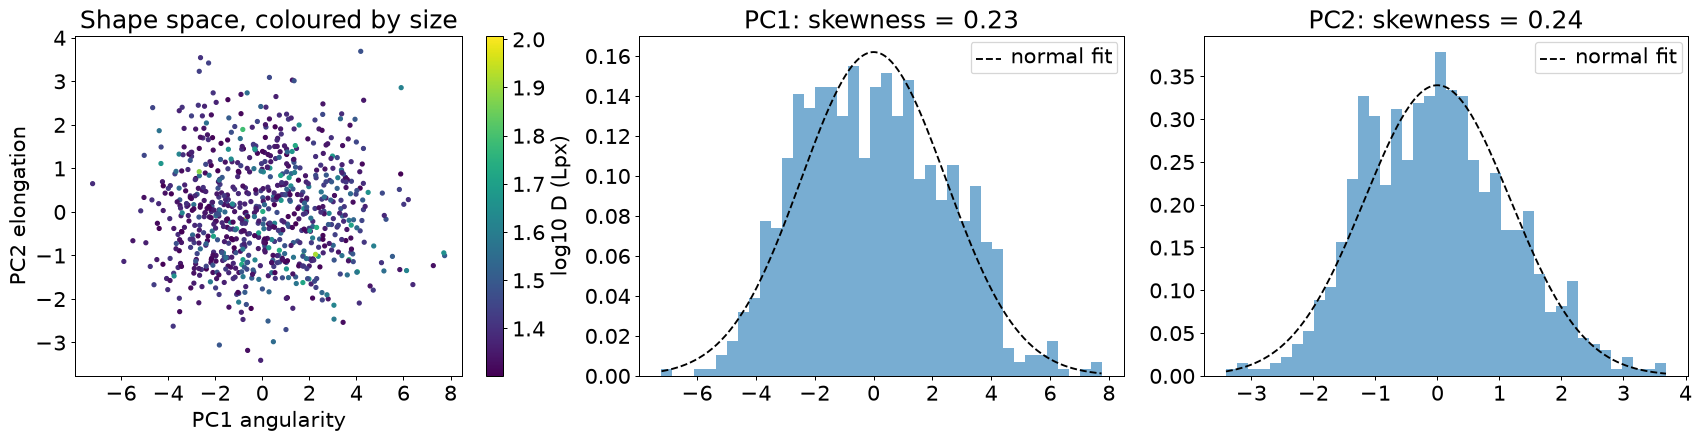

In [10]:
npc = 3
bic = {k: GaussianMixture(k, n_init=5, random_state=0).fit(Z[:, :npc]).bic(Z[:, :npc]) for k in range(1, 7)}
K = min(bic, key=bic.get)
print(f'BIC (first {npc} PCs, lower is better):', {k: round(v) for k, v in bic.items()}, '-> best K =', K)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sc = ax[0].scatter(pcs.PC1, pcs.PC2, c=np.log10(g.eq_diameter_u), s=10, cmap='viridis')
plt.colorbar(sc, ax=ax[0], label='log10 D (Lpx)'); ax[0].set_xlabel('PC1 angularity'); ax[0].set_ylabel('PC2 elongation'); ax[0].set_title('Shape space, coloured by size')
for a, pc in zip(ax[1:], ['PC1', 'PC2']):
    a.hist(pcs[pc], 40, density=True, alpha=0.6)
    xs = np.linspace(pcs[pc].min(), pcs[pc].max(), 200); a.plot(xs, stats.norm.pdf(xs, pcs[pc].mean(), pcs[pc].std()), 'k--', label='normal fit')
    dip = stats.skew(pcs[pc]); a.set_title(f'{pc}: skewness = {dip:.2f}'); a.legend()
plt.tight_layout(); plt.show()

**Reading the result.**
- **Printed line:** BIC for 1-6 groups (lower = better); the best is **1 group**.
- **Left:** each dot is one grain in shape space (PC1 = angularity, PC2 = elongation), coloured by size. One continuous
  cloud, no separate clusters; the colours are mixed, so size and shape are unrelated.
- **Centre / right:** histograms of PC1 and PC2 with a normal curve (dashed). Single peaks, no second mode.

**One shape population:** consistent with a single sediment source.

### Spatial organisation of grain shape
Are angular (or elongated) grains spatially grouped? **Moran's I** with 8-nearest-neighbour weights and a
999-permutation test. I > 0 with small p means neighbours have similar shapes (spatial clustering).

**Why.** Notebook 04 found porous zones. If angular grains gathered in some zones, shape could
explain those zones.

**How to read Moran's I:** 0 = shapes are placed at random; > 0 = neighbouring grains have similar shapes.

,Moran's I,E[I] under randomness,p (one-sided)
variable,,,
PC1 angularity,0.037,-0.002,0.018
PC2 elongation,-0.006,-0.002,0.588
grain size (log D),-0.005,-0.002,0.563


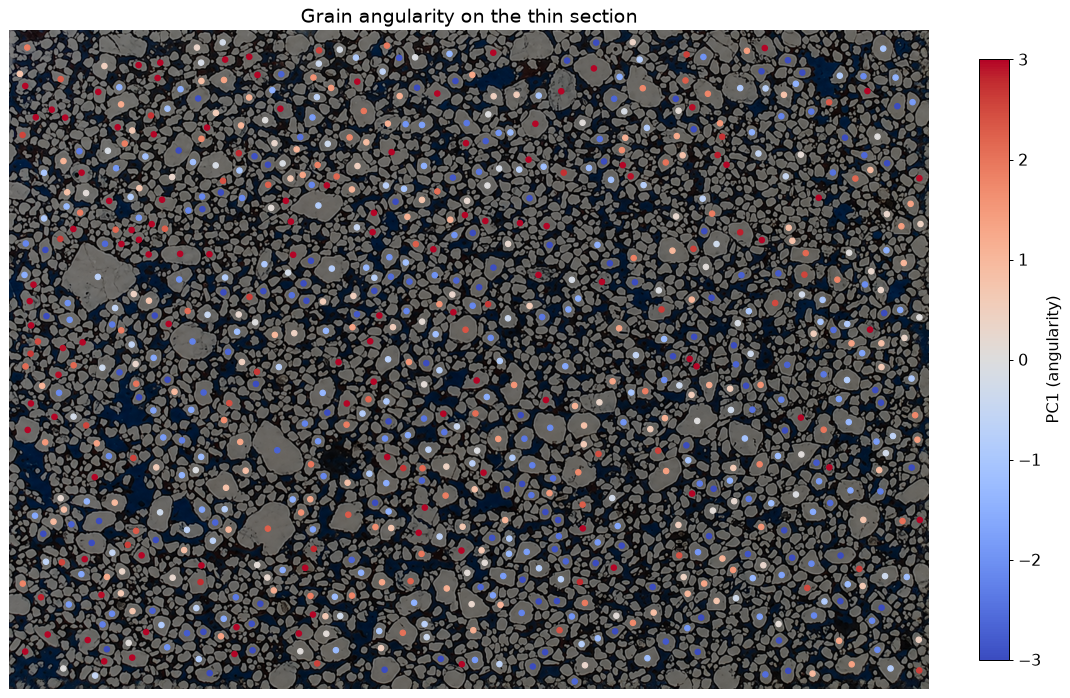

In [11]:
def morans_i(xy, v, k=8, nperm=999, seed=0):
    _, nb = cKDTree(xy).query(xy, k + 1); nb = nb[:, 1:]
    z = v - v.mean()
    I = lambda zz: len(zz) * (zz[:, None] * zz[nb]).sum() / (nb.size * (zz ** 2).sum())
    obs = I(z); rng = np.random.default_rng(seed)
    perm = np.array([I(rng.permutation(z)) for _ in range(nperm)])
    return obs, (np.sum(perm >= obs) + 1) / (nperm + 1), perm.mean()

xy_c = g[['cx', 'cy']].values
rows = []
for nm, v in [('PC1 angularity', pcs.PC1.values), ('PC2 elongation', pcs.PC2.values), ('grain size (log D)', np.log(g.eq_diameter_u.values))]:
    I, p, e = morans_i(xy_c, v); rows.append({'variable': nm, "Moran's I": I, 'E[I] under randomness': e, 'p (one-sided)': p})
moran = pd.DataFrame(rows).set_index('variable'); display(moran.round(3))

fig, ax = plt.subplots(figsize=(12, 8.5))
ax.imshow(rgb * 0.5)
sc = ax.scatter(g.cx, g.cy, c=pcs.PC1, s=18, cmap='coolwarm', vmin=-3, vmax=3)
plt.colorbar(sc, ax=ax, fraction=0.03, label='PC1 (angularity)'); ax.axis('off'); ax.set_title('Grain angularity on the thin section')
plt.tight_layout(); plt.show()

**Reading the result.**
- **Table:** Moran's I for angularity (PC1), elongation (PC2) and size, with the value expected at random and the p-value.
  All are close to 0. Only PC1 is weakly significant (I = 0.037, p = 0.018), and that disappears once aggregates are
  removed (next check).
- **Map:** each dot is a grain, coloured by angularity (blue = round, red = angular). Colours are mixed everywhere.

**Grain shape is spatially random**, so the porous zones of notebook 04 are not caused by grain shape.

### Robustness: segmentation aggregates

The most "angular" end of the morphospace (PC1 > 2) contains multi-lobed objects. Quartz grains are rarely
strongly concave, so many of these are **aggregates**: two or three touching grains the watershed did not split, or
a grain with attached cement. Objects with **solidity < 0.85** are flagged as possible aggregates (examples below).
The key results are then recomputed without them.

**Why.** If some "grains" are really two grains stuck together, they could create a false second shape family or
false clustering.

possible aggregates: 126 of 760 (17%)


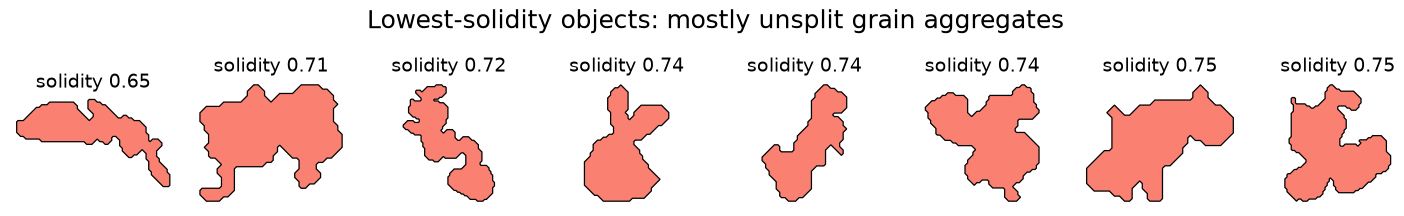

,all objects,solidity >= 0.85
n,760.000,634.000
PC1 variance %,43.301,36.129
PC2 variance %,9.847,11.136
best K (BIC),1.000,1.000
"rho(size, roundness_h)",0.055,0.059
"rho(size, A2)",0.009,0.002
Moran's I PC1,0.037,0.027
Moran p,0.018,0.074


In [12]:
g['possible_aggregate'] = g.solidity < 0.85
print(f'possible aggregates: {g.possible_aggregate.sum()} of {len(g)} ({g.possible_aggregate.mean():.0%})')
worst = g.solidity.nsmallest(8).index
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
for a, lab in zip(ax, worst):
    xy = cont[lab] - polygon_centroid(cont[lab]); s = np.sqrt(g.loc[lab, 'area'])
    a.fill(xy[:, 0] / s, -xy[:, 1] / s, color='salmon', ec='k'); a.set_aspect('equal'); a.axis('off')
    a.set_title(f'solidity {g.loc[lab, "solidity"]:.2f}', fontsize=9)
plt.suptitle('Lowest-solidity objects: mostly unsplit grain aggregates'); plt.tight_layout(); plt.show()

keep = ~g.possible_aggregate.values
Xk = StandardScaler().fit_transform(F[keep]); pk = PCA().fit(Xk); Zk = pk.transform(Xk)
bic_k = {k: GaussianMixture(k, n_init=5, random_state=0).fit(Zk[:, :3]).bic(Zk[:, :3]) for k in range(1, 7)}
gk = g[keep]
rob = pd.DataFrame({
    'all objects': {'n': len(g), 'PC1 variance %': 100 * ev[0], 'PC2 variance %': 100 * ev[1], 'best K (BIC)': K,
                    'rho(size, roundness_h)': stats.spearmanr(g.eq_diameter_u, g.roundness_h).statistic,
                    'rho(size, A2)': stats.spearmanr(g.eq_diameter_u, g.A2).statistic,
                    "Moran's I PC1": moran.loc['PC1 angularity', "Moran's I"], "Moran p": moran.loc['PC1 angularity', 'p (one-sided)']},
    'solidity >= 0.85': {'n': int(keep.sum()), 'PC1 variance %': 100 * pk.explained_variance_ratio_[0], 'PC2 variance %': 100 * pk.explained_variance_ratio_[1],
                         'best K (BIC)': min(bic_k, key=bic_k.get),
                         'rho(size, roundness_h)': stats.spearmanr(gk.eq_diameter_u, gk.roundness_h).statistic,
                         'rho(size, A2)': stats.spearmanr(gk.eq_diameter_u, gk.A2).statistic,
                         "Moran's I PC1": morans_i(gk[['cx', 'cy']].values, -gk.solidity.values)[0],
                         "Moran p": morans_i(gk[['cx', 'cy']].values, -gk.solidity.values)[1]}})
rob.round(3)

**Reading the result.**
- **Printed line:** 126 of 760 grains (17 %) have solidity < 0.85 (possible aggregates).
- **Shapes:** the 8 lowest-solidity objects, most clearly two or three grains joined together.
- **Table:** the main results with all grains and without the possible aggregates. The number of families stays 1,
  size and shape stay unrelated, and Moran's I for angularity loses its significance (p = 0.074). **The conclusions
  do not depend on the aggregates.**

*(For the filtered set, Moran's I is computed on -solidity as the angularity measure, because PC scores from a
refitted PCA are not directly comparable.)*

## 8. Grain fabric: long-axis orientation

**Why.** Water currents and compaction can align elongated grains. A preferred direction would reveal the depositional or compaction fabric and possibly the orientation of the bedding.

**Why we calculate it and why it is important.** In one sentence: this section tests **whether the elongated grains point in a preferred direction**. It is useful for these reasons:

1. **It reveals the fabric of the rock.** Currents align elongated grains during deposition, and compaction can rotate them; a preferred direction records these processes.
2. **It may indicate the bedding direction.** Grains usually lie parallel to the bedding, which is not marked on the thin section.
3. **It matters for flow.** Aligned grains can make permeability different along and across the fabric.

| What this section gives | Why it is useful |
|---|---|
| rose diagram of long axes | whether grains are aligned |
| mean direction and its significance | direction of the fabric (likely bedding) |
| strength vs grain size | shows the fabric is real, not a pixel artefact |

**What.** The long-axis direction of every clearly elongated grain (aspect ratio >= 1.3), in a rose diagram, with a test for a preferred direction.

**How.**

Orientation of the long axis of elongated grains (aspect ratio >= 1.3), measured from the horizontal image axis.
Orientations are axial data (0 = 180 deg), so the **Rayleigh test** is applied to doubled angles. A preferred
orientation would indicate current alignment or compaction fabric.

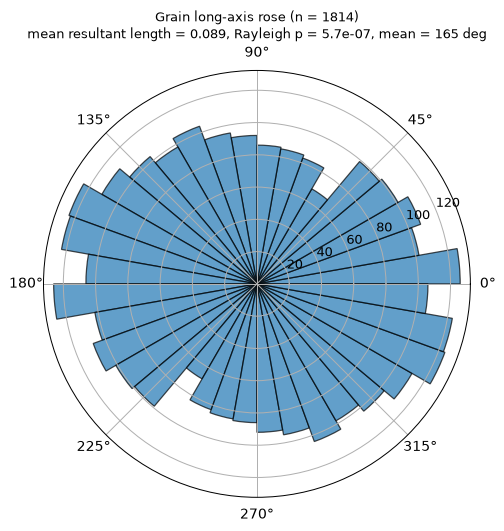

In [13]:
allg = objs[(objs.image == 'large') & (objs.phase == 'grain') & ~objs.on_border & (objs.eq_diameter_u >= 10) & (objs.aspect_ratio >= 1.3)]
alpha = np.mod(90 - allg.orientation_deg, 180)          # skimage orientation is from the row axis
n_ = len(alpha); z2 = np.exp(2j * np.radians(alpha)); Rbar = np.abs(z2.mean())
mean_dir = np.mod(np.degrees(np.angle(z2.mean())) / 2, 180)
Rn = n_ * Rbar; p_ray = np.exp(np.sqrt(1 + 4 * n_ + 4 * (n_ ** 2 - Rn ** 2)) - (1 + 2 * n_))   # Zar (2010)
fig = plt.figure(figsize=(6, 6)); axp = fig.add_subplot(projection='polar')
h, e = np.histogram(np.r_[alpha, alpha + 180], bins=36, range=(0, 360))
axp.bar(np.radians(e[:-1] + 5), h, width=np.radians(10), alpha=0.7, edgecolor='k')
axp.set_title(f'Grain long-axis rose (n = {n_})\nmean resultant length = {Rbar:.3f}, Rayleigh p = {p_ray:.2g}, mean = {mean_dir:.0f} deg')
plt.tight_layout(); plt.show()

**Reading the rose diagram.** It is a circular histogram: each petal = a direction of the grain long axis (0 deg =
horizontal in the image, 90 deg = vertical); petal length = number of grains with that direction. Each direction
appears twice (0 = 180 deg), so the diagram is symmetric. **Mean resultant length** = strength of the alignment (0 =
none, 1 = all parallel). **Rayleigh p** = chance of such alignment at random.

Result: 1,814 grains, mean resultant length 0.089, p = 6e-7, mean direction ~ 165 deg: a **weak but significant
preferred orientation, close to horizontal**. It gets stronger for larger grains (see Findings), so it is not a
pixel artefact.

## 9. Save

**What is saved** (in `outputs/`): `05_grain_shape.csv` (all shape indices, PCA scores and flags per grain),
`05_efd_coefficients.csv` (elliptic Fourier coefficients), `05_shape_moran.csv` (spatial test), plus
`05_radial_signatures.csv` and `05_harmonic_amplitudes.csv` saved in section 2 (the data for Fourier analysis).

In [14]:
out = g.drop(columns=['size_class']).join(pcs)
out.to_csv('../outputs/05_grain_shape.csv', index_label='label')
pd.DataFrame(np.array([canon(E[l]).ravel() for l in labs]), index=labs).to_csv('../outputs/05_efd_coefficients.csv', index_label='label')
moran.to_csv('../outputs/05_shape_moran.csv')
print('saved')

saved


## Findings

**Data produced (the "data for Fourier analysis")**
- `05_radial_signatures.csv`: 64 normalised centroid radii r(theta)/mean(r) for each of the 760 grains (D >= 20 Lpx).
  This is the input of the exercise figure.
- `05_harmonic_amplitudes.csv`: Fourier amplitudes A1-A24. `05_efd_coefficients.csv`: normalised elliptic Fourier
  coefficients (14 harmonics). `05_grain_shape.csv`: all shape indices, PCA scores and flags.

**Method validation**
- Synthetic shapes put their energy in the expected harmonic (ellipse A2, triangle A3, square A4, pentagon A5) and
  A1 ~ 0. Real grains have median A1 ~ 0.01, so the centroid is correct.
- **Resolution limit**: comparing the same 151 grains (D >= 20) imaged at two magnifications, harmonics 2-14
  are reproducible (Spearman rho >= ~0.7), but n > 16 are not (rho 0.3-0.5). **Form and roundness can be measured
  in these images; surface texture (n > 14) cannot.** A higher-magnification image would be needed for texture.
- 69 % of grains are star-shaped (angular backtrack <= 5 deg), as the centroid method requires. The EFD handles the rest.
- Fourier indices agree with classical descriptors: A2 vs aspect ratio rho = 0.98; harmonic roundness (A5-A14) vs
  circularity rho = -0.84 and vs solidity -0.86.

**Grain shape results**
- Typical grain: A2 ~ 0.19 (moderate elongation, median aspect ratio ~ 1.43); harmonic roundness ~ 0.08.
- **Shape is independent of grain size**: rho(size, A2) = 0.01 and rho(size, roundness) = 0.05, with no
  difference between size classes for form. The Kruskal-Wallis p = 0.009 for roundness has no trend with size.
- **Shape space**: PCA on standardised log EFD power separates two independent axes: **PC1 = angularity/irregularity**
  (43 % of variance; rho = -0.87 with circularity) and **PC2 = elongation** (10 %; rho = 0.89 with aspect ratio). These
  are the classical *roundness* and *form* components.
- **A single shape population**: BIC selects one Gaussian component, with or without the possible aggregates. There
  are no discrete shape families, which is consistent with a **single, homogeneous sediment source**. Ehrlich et al.
  (1980) used multimodal Fourier shape distributions as evidence of mixed provenance.
- **Shape is spatially random**: Moran's I for angularity is 0.03 (p = 0.07 once aggregates are removed). Shape does
  not follow the porous and tight zones found in notebook 04, which confirms that those zones are **diagenetic
  (cement), not textural**.

**Fabric**
- The long axes show a **weak but significant preferred orientation, sub-parallel to the image horizontal**
  (mean ~ 165-175 deg; Rayleigh p < 1e-5). It **strengthens for larger grains** (mean resultant length 0.10 for
  D >= 10, 0.18 for D >= 20, 0.23 for D >= 30), which rules out a pixel-grid artefact. If the section is cut
  perpendicular to bedding, this is a bedding-parallel depositional or compaction fabric. It is consistent with the
  weak vertical correlation tail in notebook 04.

**Limitations**
- About 17 % of the large objects have solidity < 0.85, mostly unsplit aggregates of touching grains. They
  inflate the angular tail of PC1, but none of the conclusions change when they are excluded.
- r(theta) depends on the centroid choice for irregular grains (Full & Ehrlich, 1982). EFD does not, and the two
  methods agree on the low harmonics.